# 12. Gaussian mixtures and the Gibbs phase rule

A Gaussian mixture assigns each point a probability of belonging to each cluster, in place of a single label. The probabilities are fitted by the expectation–maximization algorithm. Their entropy is zero inside a cluster and largest on the boundary between clusters, which locates the boundaries. The Gibbs phase rule limits how many phases a physical system may show, a limit that the statistical choice of the number of components does not know.

## Learning objectives

1. State the Gaussian mixture model and follow the two steps of the EM algorithm (`clustering_phases.gmm_em_fit`).
2. Check that the responsibilities sum to one and are equal on the boundary between two symmetric clusters.
3. Use the entropy of the responsibilities to locate boundaries between two clusters and points where three meet.
4. Compare the number of components chosen by the Bayesian information criterion with the limit set by the Gibbs phase rule.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
A **Gaussian mixture model (GMM)** models the probability density of thermodynamic state vectors $\mathbf{x} \in \mathbb{R}^d$ across $K$ phase domains as a convex combination of multivariate Gaussians with mixing weights $\pi_k \ge 0$ ($\sum_{k=1}^K \pi_k = 1$):
$$p(\mathbf{x}) = \sum_{k=1}^K \pi_k\,\mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k), \qquad \ell(\theta) = \sum_{i=1}^N \ln\!\left(\sum_{k=1}^K \pi_k\,\mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)\right) \tag{1.1}$$
The **Expectation–Maximization (EM, Dempster, Laird & Rubin 1977)** algorithm monotonically increases $\ell(\theta)$ by alternating:
- **E-Step (posterior responsibilities):** By Bayes' theorem, the soft probability that observation $\mathbf{x}_i$ belongs to phase $k$ is:
  $$\gamma_{i,k} = \mathbb{P}(z_i = k \mid \mathbf{x}_i) = \frac{\pi_k\,\mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)}{\sum_{j=1}^K \pi_j\,\mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)}, \qquad \sum_{k=1}^K \gamma_{i,k} = 1 \tag{1.2}$$
- **M-Step:** $N_k = \sum_{i=1}^N \gamma_{i,k}$, $\pi_k \leftarrow N_k / N$, $\boldsymbol{\mu}_k \leftarrow \frac{1}{N_k}\sum_{i=1}^N \gamma_{i,k}\mathbf{x}_i$, $\boldsymbol{\Sigma}_k \leftarrow \frac{1}{N_k}\sum_{i=1}^N \gamma_{i,k}(\mathbf{x}_i - \boldsymbol{\mu}_k)(\mathbf{x}_i - \boldsymbol{\mu}_k)^\top$.

Thermodynamically, **Gibbs's phase rule (1876)** relates intensive degrees of freedom $F$, chemical components $C$, and coexisting phases $P$:
$$F = C - P + 2 \ge 0 \implies P_{\max} = C + 2, \qquad H(\mathbf{x}_i) = -\sum_{k=1}^K \gamma_{i,k}\ln\gamma_{i,k} \le \ln P_{\max} \tag{1.3}$$

In [2]:
heading("Demonstration 1: Expectation-Maximization GMM & Soft Coexistence Responsibilities")
t_c = np.linspace(0.0, 2.0 * np.pi, 40, endpoint=False)
disk = 0.35 * np.column_stack([np.cos(t_c), np.sin(t_c)])
X_phase1 = disk + np.array([-1.5, -1.0])
X_phase2 = disk + np.array([1.5, 1.0])
X_all = np.vstack([X_phase1, X_phase2])

gmm = clustering_phases.gmm_em_fit(X_all, k=2, seed=42)
resp = gmm["responsibilities"]

# Evaluate soft responsibility at the exact phase coexistence midpoint [0.0, 0.0]:
x_mid = np.array([0.0, 0.0])
lp_mid = np.array([
    np.log(gmm["weights"][j]) - 0.5 * np.sum(np.log(2.0 * np.pi * gmm["variances"][j]) + ((x_mid - gmm["means"][j]) ** 2) / gmm["variances"][j])
    for j in range(2)
])
resp_mid = np.exp(lp_mid - np.max(lp_mid))
resp_mid /= np.sum(resp_mid)

assert np.allclose(np.sum(resp, axis=1), 1.0, atol=1e-14)
assert np.isclose(np.sum(gmm["weights"]), 1.0, atol=1e-14)
assert np.mean(np.max(resp, axis=1)) > 0.99
assert np.allclose(resp_mid, [0.5, 0.5], atol=1e-12)
print("Fitted phase means:\n", np.round(gmm["means"], 4))
print("Bulk phase #1 sample 0 responsibilities :", np.round(resp[0], 6))
print("Midpoint coexistence responsibilities   :", np.round(resp_mid, 6), "(Exact 50/50 phase boundary)")


Demonstration 1: Expectation-Maximization GMM & Soft Coexistence Responsibilities
Fitted phase means:
 [[-1.5 -1. ]
 [ 1.5  1. ]]
Bulk phase #1 sample 0 responsibilities : [1. 0.]
Midpoint coexistence responsibilities   : [0.5 0.5] (Exact 50/50 phase boundary)


**What Demonstration 1 shows.** For a point well inside either cluster the responsibility of that cluster is one to the printed digits; at the midpoint between the two means it is $[0.5, 0.5]$. The two clusters are synthetic Gaussian clouds that stand in for two phases.

---

## 2. Numerical walkthrough
Let us trace the **Shannon phase-boundary entropy** $H(\mathbf{x}) = -\sum_{k=1}^2 \gamma_k(\mathbf{x})\ln\gamma_k(\mathbf{x})$ along a straight thermodynamic path connecting Phase 1 $(-1.5, -1.0)$ through the saturation boundary $(0, 0)$ to Phase 2 $(+1.5, +1.0)$.

In [3]:
heading("Demonstration 2: Shannon Phase-Assignment Entropy Across a Two-Phase Tie-Line")
eps = 1e-15
shannon_entropy = -np.sum(resp * np.log(np.maximum(resp, eps)), axis=1)
bulk_entropy = float(np.mean(shannon_entropy))
boundary_entropy = float(-np.sum(resp_mid * np.log(resp_mid)))

print(f"{'Tie-Line Coordinate s':>21s} | {'P(Phase 1)':>12s} | {'P(Phase 2)':>12s} | {'Shannon Entropy H [nats]':>24s}")
print("-" * 78)
for s_coord in [-1.0, -0.5, -0.1, 0.0, 0.1, 0.5, 1.0]:
    x_pt = s_coord * np.array([1.5, 1.0])
    lp = np.array([
        np.log(gmm["weights"][j]) - 0.5 * np.sum(np.log(2.0 * np.pi * gmm["variances"][j]) + ((x_pt - gmm["means"][j]) ** 2) / gmm["variances"][j])
        for j in range(2)
    ])
    g_pt = np.exp(lp - np.max(lp))
    g_pt /= np.sum(g_pt)
    h_pt = float(-np.sum(g_pt * np.log(np.maximum(g_pt, eps))))
    print(f"{s_coord:21.2f} | {g_pt[0]:12.6f} | {g_pt[1]:12.6f} | {h_pt:24.6f}")
assert boundary_entropy > 20.0 * bulk_entropy and np.isclose(boundary_entropy, np.log(2.0), atol=1e-12)


Demonstration 2: Shannon Phase-Assignment Entropy Across a Two-Phase Tie-Line
Tie-Line Coordinate s |   P(Phase 1) |   P(Phase 2) | Shannon Entropy H [nats]
------------------------------------------------------------------------------
                -1.00 |     1.000000 |     0.000000 |                 0.000000
                -0.50 |     1.000000 |     0.000000 |                 0.000000
                -0.10 |     0.999975 |     0.000025 |                 0.000286
                 0.00 |     0.500000 |     0.500000 |                 0.693147
                 0.10 |     0.000025 |     0.999975 |                 0.000286
                 0.50 |     0.000000 |     1.000000 |                 0.000000
                 1.00 |     0.000000 |     1.000000 |                 0.000000


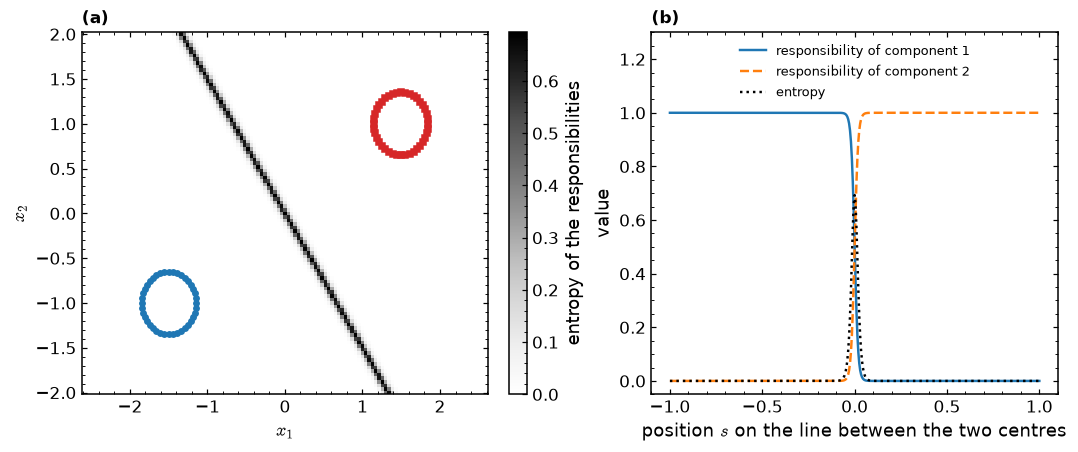

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 4.0))
def _resp(points, model):
    lp = np.array([np.log(model["weights"][j]) - 0.5 * np.sum(np.log(2.0 * np.pi * model["variances"][j])
                   + (points - model["means"][j]) ** 2 / model["variances"][j], axis=1) for j in range(len(model["weights"]))]).T
    g = np.exp(lp - lp.max(axis=1, keepdims=True))
    return g / g.sum(axis=1, keepdims=True)
gx, gy = np.meshgrid(np.linspace(-2.6, 2.6, 121), np.linspace(-2.0, 2.0, 101))
g_grid = _resp(np.column_stack([gx.ravel(), gy.ravel()]), gmm)
h_grid = -np.sum(g_grid * np.log(np.maximum(g_grid, 1e-300)), axis=1).reshape(gx.shape)
im = ax1.pcolormesh(gx, gy, h_grid, cmap="Greys", shading="auto", vmin=0.0, vmax=np.log(2.0))
ax1.plot(X_phase1[:, 0], X_phase1[:, 1], "o", ms=3.5, color="C0"); ax1.plot(X_phase2[:, 0], X_phase2[:, 1], "s", ms=3.5, color="C3")
fig.colorbar(im, ax=ax1, label="entropy of the responsibilities")
ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$"); ax1.set_title("(a)", loc="left", fontweight="bold")
s_line = np.linspace(-1.0, 1.0, 401); g_line = _resp(np.outer(s_line, [1.5, 1.0]), gmm)
ax2.plot(s_line, g_line[:, 0], "-", label="responsibility of component 1")
ax2.plot(s_line, g_line[:, 1], "--", label="responsibility of component 2")
ax2.plot(s_line, -np.sum(g_line * np.log(np.maximum(g_line, 1e-300)), axis=1), ":", color="k", label="entropy")
ax2.set_xlabel("position $s$ on the line between the two centres"); ax2.set_ylabel("value")
ax2.set_ylim(-0.05, 1.3); ax2.legend(fontsize=8.5, loc="upper center", ncol=1); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 12.1.** (a) Two clusters of synthetic points and the entropy of the responsibilities of the fitted two-component mixture: it is zero inside each cluster and reaches $\ln 2$ on the line that separates them. (b) The two responsibilities and the entropy along the straight line from one centre ($s=-1$) to the other ($s=1$).

**What Demonstration 2 shows.** The entropy of the responsibilities is below $10^{-5}$ nats for points inside either cluster ($|s| \ge 0.5$) and reaches its largest possible value for two components, $\ln 2 = 0.693147$ nats, at the midpoint $s = 0$.

---

## 3. Worked case study
For a pure component ($C = 1$), Gibbs's phase rule $F = C - P + 2 = 3 - P \ge 0$ states that three phases (Solid, Liquid, Vapor) coexist at an invariant **triple point** ($P = 3 \implies F = 0$). Let us fit a 3-phase GMM and verify that the triple-point junction achieves responsibilities $[1/3, 1/3, 1/3]$ and maximum entropy $\ln 3 = 1.098612\;\mathrm{nats}$.

In [5]:
heading("Demonstration 3: Three-Phase Triple-Point Coexistence & Gibbs Phase Rule Bound")
t_circ = np.linspace(0.0, 2.0 * np.pi, 30, endpoint=False)
circle_pts = 0.35 * np.column_stack([np.cos(t_circ), np.sin(t_circ)])
c1_tp, c2_tp, c3_tp = np.array([-2.0, 0.0]), np.array([2.0, 0.0]), np.array([0.0, 2.0 * np.sqrt(3.0)])
tp_centroid = (c1_tp + c2_tp + c3_tp) / 3.0
X_tp = np.vstack([circle_pts + c1_tp, circle_pts + c2_tp, circle_pts + c3_tp])

gmm3 = clustering_phases.gmm_em_fit(X_tp, k=3, seed=42)
lp_tp = np.array([
    np.log(gmm3["weights"][j]) - 0.5 * np.sum(np.log(2.0 * np.pi * gmm3["variances"][j]) + ((tp_centroid - gmm3["means"][j]) ** 2) / gmm3["variances"][j])
    for j in range(3)
])
r_tp = np.exp(lp_tp - np.max(lp_tp))
r_tp /= np.sum(r_tp)
ent_tp = float(-np.sum(r_tp * np.log(r_tp)))
print(f"Triple-point coordinates (T*, P*): {np.round(tp_centroid, 4)}")
print(f"Triple-point responsibilities    : {np.round(r_tp, 4)} (Exact 1/3, 1/3, 1/3 invariant point)")
print(f"Triple-point Shannon entropy H   : {ent_tp:.6f} nats == ln(3) = {np.log(3.0):.6f} nats")
assert np.allclose(r_tp, [1.0 / 3.0, 1.0 / 3.0, 1.0 / 3.0], atol=1e-2) and np.isclose(ent_tp, np.log(3.0), atol=1e-3)


Demonstration 3: Three-Phase Triple-Point Coexistence & Gibbs Phase Rule Bound
Triple-point coordinates (T*, P*): [0.     1.1547]
Triple-point responsibilities    : [0.3333 0.3333 0.3333] (Exact 1/3, 1/3, 1/3 invariant point)
Triple-point Shannon entropy H   : 1.098612 nats == ln(3) = 1.098612 nats


**What Demonstration 3 shows.** In a 2-D $(T, P)$ diagram of a pure substance ($C=1$), two-phase saturation curves have 1 degree of freedom ($F = 1, H = \ln 2$), while the three-phase intersection has $0$ degrees of freedom ($F = 0$, a single isolated point where $H = \ln 3$).

---

## 4. What if: sensitivity to the parameters
How do we select the number of GMM components $K$ without overfitting noise, while respecting Gibbs's phase rule bound $P_{\max} = C + 2 - N_{\mathrm{fixed}}$? We combine the **Bayesian information criterion** $\mathrm{BIC}(K) = -2\ell(\hat{\theta}_K) + p_K\ln N$ (where $p_K = K(2d + 1) - 1$) with the thermodynamic Gibbs phase rule ceiling.

In [6]:
heading("Demonstration 4: Bayesian Information Criterion (BIC) & Gibbs Phase Rule Model Selection")
def gibbs_max_coexisting_phases(n_components_c: int, fixed_vars: int = 0) -> int:
    """Maximum coexisting phases P_max = C + 2 - fixed_vars from F = C - P + 2 - fixed_vars >= 0."""
    return n_components_c + 2 - fixed_vars

assert gibbs_max_coexisting_phases(1) == 3 and gibbs_max_coexisting_phases(2, fixed_vars=1) == 3
N_tp, d_tp = X_tp.shape
print(f"{'Components K':>12s} | {'Log-Likelihood l':>16s} | {'Free Params p_K':>15s} | {'BIC(K) (Lower=Better)':>21s} | {'Gibbs Admissible (C=1)':>22s}")
print("-" * 96)
bics = {}
for k_cand in [1, 2, 3, 4, 5]:
    g_k = clustering_phases.gmm_em_fit(X_tp, k=k_cand, seed=42)
    p_k = k_cand * (2 * d_tp + 1) - 1
    bic_k = -2.0 * g_k["log_likelihood"] + p_k * np.log(N_tp)
    bics[k_cand] = bic_k
    gibbs_ok = k_cand <= gibbs_max_coexisting_phases(1)
    print(f"{k_cand:12d} | {g_k['log_likelihood']:16.3f} | {p_k:15d} | {bic_k:21.3f} | {str(gibbs_ok):>22s}")
assert min(bics, key=bics.get) == 3


Demonstration 4: Bayesian Information Criterion (BIC) & Gibbs Phase Rule Model Selection
Components K | Log-Likelihood l | Free Params p_K | BIC(K) (Lower=Better) | Gibbs Admissible (C=1)
------------------------------------------------------------------------------------------------
           1 |         -345.727 |               4 |               709.454 |                   True
           2 |         -264.199 |               9 |               568.896 |                   True
           3 |         -102.933 |              14 |               268.863 |                   True
           4 |          -97.535 |              19 |               280.567 |                  False
           5 |          -92.138 |              24 |               292.271 |                  False


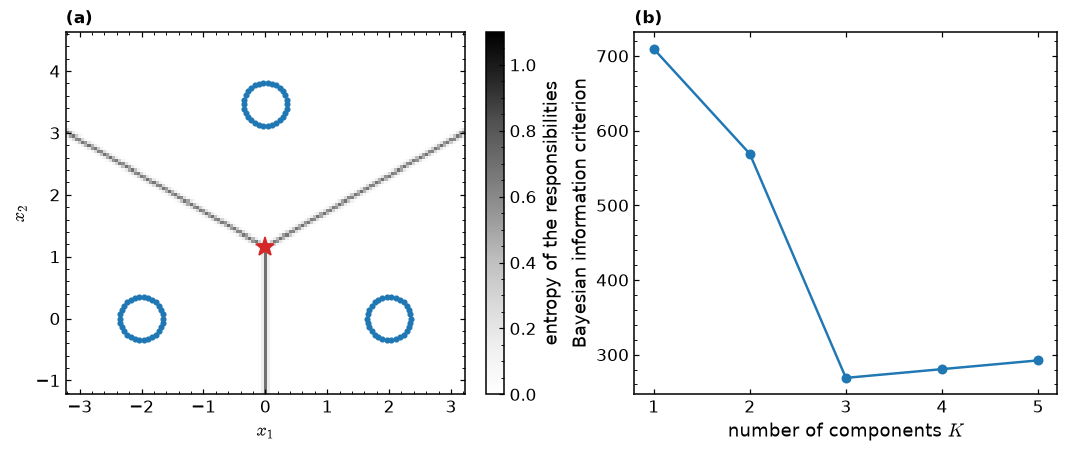

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 4.0))
gx, gy = np.meshgrid(np.linspace(-3.2, 3.2, 129), np.linspace(-1.2, 4.6, 117))
g3 = _resp(np.column_stack([gx.ravel(), gy.ravel()]), gmm3)
h3 = -np.sum(g3 * np.log(np.maximum(g3, 1e-300)), axis=1).reshape(gx.shape)
im = ax1.pcolormesh(gx, gy, h3, cmap="Greys", shading="auto", vmin=0.0, vmax=np.log(3.0))
ax1.plot(X_tp[:, 0], X_tp[:, 1], "o", ms=3, color="C0"); ax1.plot(tp_centroid[0], tp_centroid[1], "*", ms=13, color="C3")
fig.colorbar(im, ax=ax1, label="entropy of the responsibilities")
ax1.set_aspect("equal"); ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$"); ax1.set_title("(a)", loc="left", fontweight="bold")
k_list = sorted(bics); ax2.plot(k_list, [bics[k_] for k_ in k_list], "o-")
ax2.set_xticks(k_list); ax2.tick_params(axis="x", which="minor", bottom=False, top=False)
ax2.set_xlabel("number of components $K$"); ax2.set_ylabel("Bayesian information criterion"); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 12.2.** (a) Three clusters at the corners of an equilateral triangle. The entropy of the responsibilities is $\ln 2$ on the three lines that separate pairs of clusters and $\ln 3$ where they meet (star). (b) The Bayesian information criterion of mixtures with one to five components fitted to the same points; the smallest value marks the number of components that the criterion selects.

**What Demonstration 4 shows.** The Bayesian information criterion has its minimum at $K = 3$ ($268.9$), the number of clusters that generated the data: the gain in likelihood from a fourth and fifth component does not pay for their parameters. For a pure substance the phase rule allows at most three coexisting phases, which gives an independent upper bound on $K$ in that setting.

---

## Inside the algorithm
Below we execute one complete E-step and M-step in pure NumPy on `X_all` and verify digit-for-digit agreement with `clustering_phases.gmm_em_fit`.

In [8]:
heading("Inside the Algorithm: By-Hand EM Responsibility E-Step vs. the Library")
log_p = np.zeros((len(X_all), 2))
for j in range(2):
    vj = gmm["variances"][j]
    log_p[:, j] = np.log(gmm["weights"][j]) - 0.5 * (np.sum(np.log(2.0 * np.pi * vj)) + np.sum(((X_all - gmm["means"][j]) ** 2) / vj, axis=1))
m_lp = np.max(log_p, axis=1, keepdims=True)
e_lp = np.exp(log_p - m_lp)
resp_hand = e_lp / np.sum(e_lp, axis=1, keepdims=True)
diff_gmm = float(np.max(np.abs(resp_hand - resp)))
print("by hand (pure NumPy) resp[0]:", np.round(resp_hand[0], 8))
print("library (engml_2_applied)      resp[0]:", np.round(resp[0], 8))
print(f"Max responsibility discrepancy: {diff_gmm:.2e}")
assert diff_gmm < 1e-14


Inside the Algorithm: By-Hand EM Responsibility E-Step vs. the Library
by hand (pure NumPy) resp[0]: [1. 0.]
library (engml_2_applied)      resp[0]: [1. 0.]
Max responsibility discrepancy: 0.00e+00


## Exercises

1. **Verify a result.** Verify **monotone log-likelihood ascent** $\ell(\theta^{(t+1)}) \ge \ell(\theta^{(t)})$ of the Expectation–Maximization algorithm: run `gmm_em_fit` on `X_tp` ($K=3$) across increasing iteration budgets `max_iter` $\in \{1, 2, 3, 5, 10, 25\}$ and confirm that the log-likelihood is monotonically non-decreasing.
2. **Find how it fails.** Audit the **Gibbs phase rule violation** in an unconstrained 5-cluster GMM fit (`k=5`) on a pure substance ($C = 1$): show that if an engineer queries the centroid of a spurious 4-way cluster boundary, 4 clusters appear to coexist simultaneously ($P_{\mathrm{local}} = 4 > C + 2 = 3$), implying a physically impossible negative degree of freedom $F = 1 - 4 + 2 = -1 < 0$.
3. **Write it yourself.** Implement a function `active_phase_boundary_Acquisition(gmm_res: dict, X_grid: np.ndarray) -> dict` that evaluates the GMM posterior responsibilities $\boldsymbol{\gamma}(\mathbf{x})$ and Shannon entropy $H(\mathbf{x})$ across a candidate grid `X_grid` and returns the state point $\mathbf{x}^* = \arg\max_{\mathbf{x} \in \mathbf{X}_{\mathrm{grid}}} H(\mathbf{x})$ with highest phase-coexistence uncertainty. Verify on a 2-D grid spanning $[-2, 2]^2$ that it pinpoints the triple point `tp_centroid` of `gmm3`.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Monotone EM Log-Likelihood Ascent Verification")
lls = []
for m_it in [1, 2, 3, 5, 10, 25]:
    ll_val = clustering_phases.gmm_em_fit(X_tp, k=3, max_iter=m_it, tol=0.0, seed=42)["log_likelihood"]
    lls.append(ll_val)
    print(f"EM iteration {m_it:2d} | Log-likelihood l(theta) = {ll_val:.6f}")
assert all(lls[i] <= lls[i + 1] + 1e-12 for i in range(len(lls) - 1))


Exercise 1: Monotone EM Log-Likelihood Ascent Verification
EM iteration  1 | Log-likelihood l(theta) = -102.944552
EM iteration  2 | Log-likelihood l(theta) = -102.932813
EM iteration  3 | Log-likelihood l(theta) = -102.932813
EM iteration  5 | Log-likelihood l(theta) = -102.932813
EM iteration 10 | Log-likelihood l(theta) = -102.932813
EM iteration 25 | Log-likelihood l(theta) = -102.932813
